### Create inventory simulation configuration

In [1]:
import json
from pathlib import Path

# Resolve project root.
CURRENT_DIR = Path.cwd()

if CURRENT_DIR.name == "notebooks":
    PROJECT_ROOT = CURRENT_DIR.parent
else:
    PROJECT_ROOT = CURRENT_DIR

# Configuration directory.
METADATA_DIR = PROJECT_ROOT / "data" / "metadata"
METADATA_DIR.mkdir(parents=True, exist_ok=True)

# Inventory simulation assumptions.
INVENTORY_CONFIG = {
    "project": "AI Retail Demand Intelligence",

    "inventory_policy": {
        "method": "Periodic Review Order-Up-To Policy",
        "review_period_days": 7,
        "target_cycle_service_level": 0.90
    },

    "lead_time_scenarios": [
        {
            "scenario": "short_lead_time",
            "lead_time_days": 7
        },
        {
            "scenario": "medium_lead_time",
            "lead_time_days": 14
        },
        {
            "scenario": "long_lead_time",
            "lead_time_days": 21
        }
    ],

    "forecast": {
        "selected_model": "TFT",
        "forecast_horizon": 28,
        "quantiles": [0.10, 0.50, 0.90],
        "point_forecast": "P50",
        "upper_demand_forecast": "P90"
    },

    "evaluation": {
        "metrics": [
            "cycle_service_level",
            "fill_rate",
            "stockout_rate",
            "stockout_days",
            "average_inventory"
        ]
    },

    "initial_inventory": {
        "method": "historical_demand_based_initialisation",
        "value": None
    },

    "assumptions": [
        "Inventory parameters are simulation assumptions, not observed M5 data.",
        "Supplier lead time is assumed constant within each scenario.",
        "Inventory is reviewed every seven days.",
        "Demand is fulfilled from available inventory.",
        "Actual unit costs and ordering costs are unavailable.",
        "The simulation will not claim real-world cost savings."
    ]
}

# Save configuration.
CONFIG_PATH = METADATA_DIR / "inventory_simulation_config.json"

with open(CONFIG_PATH, "w", encoding="utf-8") as file:
    json.dump(
        INVENTORY_CONFIG,
        file,
        indent=4
    )

print("Inventory simulation configuration created.")
print(f"Configuration path: {CONFIG_PATH}")
print("\nLead-time scenarios:")

for scenario in INVENTORY_CONFIG["lead_time_scenarios"]:
    print(
        f"{scenario['scenario']}: "
        f"{scenario['lead_time_days']} days"
    )

print("\nReview period:",
      INVENTORY_CONFIG["inventory_policy"]["review_period_days"])

print("Target service level:",
      INVENTORY_CONFIG["inventory_policy"]["target_cycle_service_level"])

Inventory simulation configuration created.
Configuration path: c:\Users\cjc72\Desktop\SalesForecasting\AI-Retail-Demand-Intelligence\data\metadata\inventory_simulation_config.json

Lead-time scenarios:
short_lead_time: 7 days
medium_lead_time: 14 days
long_lead_time: 21 days

Review period: 7
Target service level: 0.9


### Audit the forecasting outputs

In [26]:
import copy
import numpy as np
import pandas as pd
import torch

from pathlib import Path
from torch import nn
from pytorch_forecasting import TemporalFusionTransformer
from pytorch_forecasting.metrics import QuantileLoss

FOLD_CONFIG = {
    1: {"origin": 1801, "target_start": 1802, "target_end": 1829},
    2: {"origin": 1829, "target_start": 1830, "target_end": 1857},
    3: {"origin": 1857, "target_start": 1858, "target_end": 1885}
}

CHECKPOINT_DIR = (
    PROJECT_ROOT
    / "models"
    / "tft"
    / "artifacts"
    / "development_training"
    / "tft"
    / "checkpoints"
    / "baseline"
)

TFT_DATA_DIR = PROJECT_ROOT / "data" / "processed" / "tft"

PREDICTION_DIR = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "model_comparison"
    / "predictions"
)

PREDICTION_DIR.mkdir(parents=True, exist_ok=True)

ACTUALS_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "daily_model_features.parquet"
)

print("Development folds:", list(FOLD_CONFIG))
print("Prediction directory:", PREDICTION_DIR)

Development folds: [1, 2, 3]
Prediction directory: c:\Users\cjc72\Desktop\SalesForecasting\AI-Retail-Demand-Intelligence\data\processed\model_comparison\predictions


In [27]:
development_predictions = {}

for fold, config in FOLD_CONFIG.items():

    print(f"\nProcessing Fold {fold}...")

    checkpoint_path = (
        CHECKPOINT_DIR
        / f"development_fold_{fold}_baseline.ckpt"
    )

    validation_path = (
        TFT_DATA_DIR
        / f"development_fold_{fold}_validation.pt"
    )

    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=False
    )

    validation_dataset = torch.load(
        validation_path,
        map_location="cpu",
        weights_only=False
    )

    # Reconstruct the model using the complete saved configuration.
    saved_hparams = copy.deepcopy(
        checkpoint["hyper_parameters"]
    )

    saved_hparams["loss"] = QuantileLoss(
        quantiles=[0.1, 0.5, 0.9]
    )

    saved_hparams["logging_metrics"] = nn.ModuleList()

    model = TemporalFusionTransformer.from_dataset(
        validation_dataset,
        **saved_hparams
    )

    load_result = model.load_state_dict(
        checkpoint["state_dict"],
        strict=True
    )

    assert not load_result.missing_keys
    assert not load_result.unexpected_keys

    model = model.cpu()
    model.eval()

    assert list(model.loss.quantiles) == [0.1, 0.5, 0.9]

    validation_dataloader = validation_dataset.to_dataloader(
        train=False,
        batch_size=64,
        num_workers=0
    )

    # Generate quantile predictions and retrieve corresponding actuals.
    result = model.predict(
        validation_dataloader,
        mode="quantiles",
        return_index=True,
        return_y=True,
        trainer_kwargs={
            "accelerator": "cpu",
            "devices": 1,
            "logger": False,
            "enable_checkpointing": False
        }
    )

    predictions = result.output.detach().cpu().numpy()
    actuals = result.y[0].detach().cpu().numpy()
    prediction_index = result.index.reset_index(drop=True)

    # Validate output dimensions and forecast origin.
    assert predictions.shape == (200, 28, 3)
    assert actuals.shape == (200, 28)
    assert prediction_index["id"].nunique() == 200
    assert prediction_index["time_idx"].eq(
        config["target_start"]
    ).all()

    # Construct the prediction table.
    fold_rows = []

    for i, row in prediction_index.iterrows():

        for h in range(28):

            fold_rows.append({
                "id": row["id"],
                "origin_day_num": config["origin"],
                "target_day_num": config["target_start"] + h,
                "horizon": h + 1,
                "y_true": float(actuals[i, h]),
                "p10": float(predictions[i, h, 0]),
                "p50": float(predictions[i, h, 1]),
                "p90": float(predictions[i, h, 2])
            })

    fold_frame = pd.DataFrame(fold_rows)

    # Validate forecast keys and values.
    assert len(fold_frame) == 5600
    assert fold_frame["id"].nunique() == 200

    assert fold_frame["origin_day_num"].eq(
        config["origin"]
    ).all()

    assert fold_frame["target_day_num"].min() == (
        config["target_start"]
    )

    assert fold_frame["target_day_num"].max() == (
        config["target_end"]
    )

    assert not fold_frame.duplicated(
        ["id", "origin_day_num", "target_day_num", "horizon"]
    ).any()

    assert np.isfinite(
        fold_frame[
            ["y_true", "p10", "p50", "p90"]
        ].to_numpy()
    ).all()

    development_predictions[fold] = fold_frame

    print("Prediction shape:", fold_frame.shape)
    print("Unique series:", fold_frame["id"].nunique())
    print("Forecast origin:", config["origin"])

    del model, checkpoint, validation_dataset
    del validation_dataloader, result


Processing Fold 1...


c:\Users\cjc72\Desktop\SalesForecasting\AI-Retail-Demand-Intelligence\.venv\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.6.1 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\Users\cjc72\Desktop\SalesForecasting\AI-Retail-Demand-Intelligence\.venv\Lib\site-packages\lightning\pytorch\utilities\parsing.py:213: Attribute 'loss' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['loss'])`.
c:\Users\cjc72\Desktop\SalesForecasting\AI-Retail-Demand-Intelligence\.venv\Lib\site-packages\lightning\pytorch\utilities\parsing.py:213: Attribute 'logging_metrics' is an instance of `nn.Module` and is already saved during checkpointing. I

Prediction shape: (5600, 8)
Unique series: 200
Forecast origin: 1801

Processing Fold 2...


c:\Users\cjc72\Desktop\SalesForecasting\AI-Retail-Demand-Intelligence\.venv\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.6.1 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\Users\cjc72\Desktop\SalesForecasting\AI-Retail-Demand-Intelligence\.venv\Lib\site-packages\lightning\pytorch\utilities\parsing.py:213: Attribute 'loss' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['loss'])`.
c:\Users\cjc72\Desktop\SalesForecasting\AI-Retail-Demand-Intelligence\.venv\Lib\site-packages\lightning\pytorch\utilities\parsing.py:213: Attribute 'logging_metrics' is an instance of `nn.Module` and is already saved during checkpointing. I

Prediction shape: (5600, 8)
Unique series: 200
Forecast origin: 1829

Processing Fold 3...


c:\Users\cjc72\Desktop\SalesForecasting\AI-Retail-Demand-Intelligence\.venv\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.6.1 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\Users\cjc72\Desktop\SalesForecasting\AI-Retail-Demand-Intelligence\.venv\Lib\site-packages\lightning\pytorch\utilities\parsing.py:213: Attribute 'loss' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['loss'])`.
c:\Users\cjc72\Desktop\SalesForecasting\AI-Retail-Demand-Intelligence\.venv\Lib\site-packages\lightning\pytorch\utilities\parsing.py:213: Attribute 'logging_metrics' is an instance of `nn.Module` and is already saved during checkpointing. I

Prediction shape: (5600, 8)
Unique series: 200
Forecast origin: 1857


In [28]:
all_fold_ids = sorted(
    development_predictions[1]["id"].unique()
)

assert all(
    sorted(frame["id"].unique()) == all_fold_ids
    for frame in development_predictions.values()
)

actual_verification = []

for fold, config in FOLD_CONFIG.items():

    fold_frame = development_predictions[fold]

    target_days = [
        f"d_{day}"
        for day in range(
            config["target_start"],
            config["target_end"] + 1
        )
    ]

    source_actuals = pd.read_parquet(
        ACTUALS_PATH,
        columns=["id", "d", "sales"],
        filters=[
            ("d", "in", target_days),
            ("id", "in", all_fold_ids)
        ]
    )

    source_actuals = source_actuals.rename(
        columns={
            "d": "target_day",
            "sales": "source_actual"
        }
    )

    source_actuals["target_day_num"] = (
        source_actuals["target_day"]
        .str.replace("d_", "", regex=False)
        .astype("int32")
    )

    comparison = fold_frame[
        ["id", "target_day_num", "y_true"]
    ].merge(
        source_actuals[
            ["id", "target_day_num", "source_actual"]
        ],
        on=["id", "target_day_num"],
        how="outer",
        indicator=True,
        validate="one_to_one"
    )

    matched = comparison["_merge"].eq("both")

    assert len(comparison) == 5600
    assert matched.all()

    exact_matches = np.isclose(
        comparison.loc[matched, "y_true"],
        comparison.loc[matched, "source_actual"]
    )

    assert exact_matches.all()

    actual_verification.append({
        "fold": fold,
        "observations": len(comparison),
        "matched": int(matched.sum()),
        "mismatches": int((~exact_matches).sum()),
        "max_absolute_difference": float(
            np.abs(
                comparison.loc[matched, "y_true"]
                - comparison.loc[matched, "source_actual"]
            ).max()
        )
    })

actual_verification_df = pd.DataFrame(actual_verification)

display(actual_verification_df)

,fold,observations,matched,mismatches,max_absolute_difference
0,1,5600,5600,0,0.0
1,2,5600,5600,0,0.0
2,3,5600,5600,0,0.0


In [29]:
development_predictions_df = pd.concat(
    development_predictions.values(),
    ignore_index=True
)

assert len(development_predictions_df) == 16800
assert development_predictions_df["id"].nunique() == 200
assert development_predictions_df["origin_day_num"].nunique() == 3

assert not development_predictions_df.duplicated(
    ["id", "origin_day_num", "target_day_num", "horizon"]
).any()

prediction_output_path = (
    PREDICTION_DIR
    / "tft_development_predictions.parquet"
)

development_predictions_df.to_parquet(
    prediction_output_path,
    index=False
)

print("Combined development predictions:", development_predictions_df.shape)
print("Saved to:", prediction_output_path)

display(development_predictions_df.head())

Combined development predictions: (16800, 8)
Saved to: c:\Users\cjc72\Desktop\SalesForecasting\AI-Retail-Demand-Intelligence\data\processed\model_comparison\predictions\tft_development_predictions.parquet


,id,origin_day_num,target_day_num,horizon,y_true,p10,p50,p90
0,FOODS_1_020_WI_2_evaluation,1801,1802,1,0.0,-0.024944,-0.018651,0.082661
1,FOODS_1_020_WI_2_evaluation,1801,1803,2,0.0,-0.029073,-0.014141,0.082359
2,FOODS_1_020_WI_2_evaluation,1801,1804,3,2.0,-0.028801,-0.013986,0.083821
3,FOODS_1_020_WI_2_evaluation,1801,1805,4,3.0,-0.024009,-0.015558,0.077889
4,FOODS_1_020_WI_2_evaluation,1801,1806,5,3.0,-0.032372,-0.014451,0.096009


In [30]:
diagnostic_rows = []

for fold, frame in development_predictions.items():

    for quantile in ["p10", "p50", "p90"]:

        diagnostic_rows.append({
            "fold": fold,
            "quantile": quantile.upper(),
            "negative_count": int((frame[quantile] < 0).sum()),
            "negative_rate": float((frame[quantile] < 0).mean()),
            "minimum": float(frame[quantile].min()),
            "maximum": float(frame[quantile].max()),
            "mean": float(frame[quantile].mean())
        })

quantile_diagnostics = pd.DataFrame(diagnostic_rows)

crossing_diagnostics = pd.DataFrame([
    {
        "fold": fold,
        "p10_above_p50_count": int(
            (frame["p10"] > frame["p50"]).sum()
        ),
        "p10_above_p50_rate": float(
            (frame["p10"] > frame["p50"]).mean()
        ),
        "p50_above_p90_count": int(
            (frame["p50"] > frame["p90"]).sum()
        ),
        "p50_above_p90_rate": float(
            (frame["p50"] > frame["p90"]).mean()
        )
    }
    for fold, frame in development_predictions.items()
])

print("Quantile crossing diagnostics:")
display(crossing_diagnostics)

print("\nNegative forecast diagnostics:")
display(quantile_diagnostics)

Quantile crossing diagnostics:


,fold,p10_above_p50_count,p10_above_p50_rate,p50_above_p90_count,p50_above_p90_rate
0,1,681,0.121607,0,0.0
1,2,3,0.000536,0,0.0
2,3,0,0.000000,0,0.0



Negative forecast diagnostics:


,fold,quantile,negative_count,negative_rate,minimum,maximum,mean
0,1,P10,3616,0.645714,-0.643469,30.053648,0.313672
1,1,P50,1442,0.257500,-0.201139,42.658730,1.155766
2,1,P90,1,0.000179,-0.011299,54.231571,3.332373
3,2,P10,3725,0.665179,-0.381299,28.486946,0.335276
4,2,P50,789,0.140893,-0.040425,46.380402,1.418115
5,2,P90,0,0.000000,0.000454,65.515808,3.706220
6,3,P10,4104,0.732857,-0.701112,28.962997,0.265198
7,3,P50,817,0.145893,-0.351892,42.714306,1.159135
8,3,P90,0,0.000000,0.017730,56.949287,3.466471


In [31]:
fold_summary = []

for fold, frame in development_predictions.items():

    fold_summary.append({
        "fold": fold,
        "observations": len(frame),
        "actual_mean": frame["y_true"].mean(),
        "actual_zero_rate": (frame["y_true"] == 0).mean(),
        "p10_p50_crossing_rate": (
            frame["p10"] > frame["p50"]
        ).mean(),
        "p50_p90_crossing_rate": (
            frame["p50"] > frame["p90"]
        ).mean(),
        "negative_p10_rate": (
            frame["p10"] < 0
        ).mean(),
        "negative_p50_rate": (
            frame["p50"] < 0
        ).mean(),
        "negative_p90_rate": (
            frame["p90"] < 0
        ).mean()
    })

fold_summary_df = pd.DataFrame(fold_summary)

display(
    fold_summary_df.round(4)
)

,fold,observations,actual_mean,actual_zero_rate,p10_p50_crossing_rate,p50_p90_crossing_rate,negative_p10_rate,negative_p50_rate,negative_p90_rate
0,1,5600,1.6266,0.5621,0.1216,0.0,0.6457,0.2575,0.0002
1,2,5600,1.7804,0.5436,0.0005,0.0,0.6652,0.1409,0.0000
2,3,5600,1.6009,0.5420,0.0000,0.0,0.7329,0.1459,0.0000


### Post-process TFT Forecasts

This step corrected invalid TFT predictions by applying non-negative clipping and quantile rearrangement. Negative forecasts were set to zero, and P10, P50 and P90 predictions were sorted to ensure they remain in the correct quantile order.

The original predictions were preserved for comparison. These adjustments enforce valid forecast constraints but do not guarantee improved probabilistic calibration.

In [ ]:
import numpy as np
import pandas as pd

RAW_PREDICTIONS_PATH = (
    PROJECT_ROOT
    / "data/processed/model_comparison/predictions/tft_development_predictions.parquet"
)

POSTPROCESSED_PATH = (
    PROJECT_ROOT
    / "data/processed/model_comparison/predictions/tft_development_predictions_postprocessed.parquet"
)

raw_predictions = pd.read_parquet(RAW_PREDICTIONS_PATH)

quantile_columns = ["p10", "p50", "p90"]

# Apply non-negative clipping, followed by quantile rearrangement.
corrected_quantiles = np.sort(
    np.maximum(raw_predictions[quantile_columns].to_numpy(), 0),
    axis=1
)

postprocessed_predictions = raw_predictions.copy()
postprocessed_predictions[quantile_columns] = corrected_quantiles

# Verify that the corrections satisfy the required constraints.
assert (postprocessed_predictions[quantile_columns] >= 0).all().all()
assert (
    postprocessed_predictions["p10"] <= postprocessed_predictions["p50"]
).all()
assert (
    postprocessed_predictions["p50"] <= postprocessed_predictions["p90"]
).all()

assert len(postprocessed_predictions) == len(raw_predictions)

postprocessed_predictions.to_parquet(
    POSTPROCESSED_PATH,
    index=False
)

print("Post-processed predictions:", postprocessed_predictions.shape)
print("Saved to:", POSTPROCESSED_PATH)


def calculate_forecast_metrics(data):
    actual = data["y_true"].to_numpy()
    p10 = data["p10"].to_numpy()
    p50 = data["p50"].to_numpy()
    p90 = data["p90"].to_numpy()

    def pinball_loss(y, prediction, quantile):
        error = y - prediction
        return np.mean(
            np.maximum(quantile * error, (quantile - 1) * error)
        )

    return {
        "observations": len(data),
        "MAE_P50": np.mean(np.abs(actual - p50)),
        "RMSE_P50": np.sqrt(np.mean((actual - p50) ** 2)),
        "WAPE_P50": np.sum(np.abs(actual - p50)) / np.sum(np.abs(actual)),
        "P10_pinball": pinball_loss(actual, p10, 0.1),
        "P50_pinball": pinball_loss(actual, p50, 0.5),
        "P90_pinball": pinball_loss(actual, p90, 0.9),
        "P10_coverage": np.mean(actual <= p10),
        "P90_coverage": np.mean(actual <= p90),
        "interval_coverage": np.mean(
            (actual >= p10) & (actual <= p90)
        ),
        "interval_width": np.mean(p90 - p10),
    }


comparison_rows = []

for fold in sorted(raw_predictions["origin_day_num"].unique()):
    raw_fold = raw_predictions[
        raw_predictions["origin_day_num"] == fold
    ]
    corrected_fold = postprocessed_predictions[
        postprocessed_predictions["origin_day_num"] == fold
    ]

    for version, data in [
        ("Raw", raw_fold),
        ("Postprocessed", corrected_fold)
    ]:
        metrics = calculate_forecast_metrics(data)

        comparison_rows.append({
            "origin_day_num": fold,
            "version": version,
            **metrics
        })

postprocessing_comparison = pd.DataFrame(comparison_rows)

display(
    postprocessing_comparison.round(4)
)

# Summarize the remaining constraint violations.
constraint_summary = (
    postprocessed_predictions
    .groupby("origin_day_num")
    .apply(
        lambda group: pd.Series({
            "negative_forecast_rate": (
                group[quantile_columns] < 0
            ).to_numpy().mean(),
            "p10_p50_crossing_rate": (
                group["p10"] > group["p50"]
            ).mean(),
            "p50_p90_crossing_rate": (
                group["p50"] > group["p90"]
            ).mean(),
        }),
        include_groups=False
    )
    .reset_index()
)

display(constraint_summary.round(6))

Post-processed predictions: (16800, 8)
Saved to: c:\Users\cjc72\Desktop\SalesForecasting\AI-Retail-Demand-Intelligence\data\processed\model_comparison\predictions\tft_development_predictions_postprocessed.parquet


,origin_day_num,version,observations,MAE_P50,RMSE_P50,WAPE_P50,P10_pinball,P50_pinball,P90_pinball,P10_coverage,P90_coverage,interval_coverage,interval_width
0,1801,Raw,5600,1.0188,2.2283,0.6263,0.1477,0.5094,0.3257,0.1457,0.8959,0.7502,3.0187
1,1801,Postprocessed,5600,1.0161,2.2270,0.6247,0.1463,0.5080,0.3257,0.5670,0.8961,0.7661,3.0058
2,1829,Raw,5600,1.1010,2.4945,0.6184,0.1638,0.5505,0.3498,0.1096,0.8996,0.7900,3.3709
3,1829,Postprocessed,5600,1.1002,2.4944,0.6180,0.1622,0.5501,0.3498,0.5470,0.8996,0.7900,3.3552
4,1857,Raw,5600,1.0177,2.3555,0.6357,0.1546,0.5089,0.3251,0.0611,0.9064,0.8454,3.2013
5,1857,Postprocessed,5600,1.0163,2.3554,0.6348,0.1524,0.5081,0.3251,0.5461,0.9064,0.8454,3.1797


,origin_day_num,negative_forecast_rate,p10_p50_crossing_rate,p50_p90_crossing_rate
0,1801,0.0,0.0,0.0
1,1829,0.0,0.0,0.0
2,1857,0.0,0.0,0.0


In [33]:
PROTECTION_PERIODS = [14, 21, 28]

cumulative_records = []

for (origin, series_id), group in (
    postprocessed_predictions
    .groupby(["origin_day_num", "id"])
):
    group = group.sort_values("horizon")

    actual = group["y_true"].to_numpy()
    forecast = group["p50"].to_numpy()

    for period in PROTECTION_PERIODS:
        cumulative_actual = actual[:period].sum()
        cumulative_forecast = forecast[:period].sum()

        cumulative_records.append({
            "origin_day_num": origin,
            "id": series_id,
            "protection_period": period,
            "cumulative_actual": cumulative_actual,
            "cumulative_p50": cumulative_forecast,
            "cumulative_error": (
                cumulative_actual - cumulative_forecast
            )
        })

cumulative_demand_errors = pd.DataFrame(cumulative_records)

assert len(cumulative_demand_errors) == 200 * 3 * 3
assert cumulative_demand_errors["cumulative_error"].notna().all()

CUMULATIVE_ERROR_PATH = (
    PROJECT_ROOT
    / "data/processed/model_comparison/predictions/"
    / "tft_cumulative_demand_errors.parquet"
)

cumulative_demand_errors.to_parquet(
    CUMULATIVE_ERROR_PATH,
    index=False
)

print("Cumulative demand records:", cumulative_demand_errors.shape)
print("Saved to:", CUMULATIVE_ERROR_PATH)

cumulative_error_summary = (
    cumulative_demand_errors
    .groupby("protection_period")
    .agg(
        observations=("cumulative_error", "size"),
        mean_actual=("cumulative_actual", "mean"),
        mean_forecast=("cumulative_p50", "mean"),
        mean_error=("cumulative_error", "mean"),
        median_error=("cumulative_error", "median"),
        error_std=("cumulative_error", "std"),
        error_p90=("cumulative_error", lambda x: x.quantile(0.90)),
        error_p95=("cumulative_error", lambda x: x.quantile(0.95)),
        underforecast_rate=("cumulative_error", lambda x: (x > 0).mean())
    )
    .reset_index()
)

display(cumulative_error_summary.round(4))

Cumulative demand records: (1800, 6)
Saved to: c:\Users\cjc72\Desktop\SalesForecasting\AI-Retail-Demand-Intelligence\data\processed\model_comparison\predictions\tft_cumulative_demand_errors.parquet


,protection_period,observations,mean_actual,mean_forecast,mean_error,median_error,error_std,error_p90,error_p95,underforecast_rate
0,14,600,23.9817,18.2046,5.7770,3.8553,17.8502,17.0454,25.6313,0.7433
1,21,600,36.0500,26.9142,9.1358,5.6604,22.4128,23.8642,41.6197,0.7700
2,28,600,46.7400,34.8903,11.8497,7.8262,25.5286,29.9154,47.1570,0.7883


In [35]:
cumulative_demand_errors["relative_error"] = (
    cumulative_demand_errors["cumulative_error"]
    / cumulative_demand_errors["cumulative_actual"].clip(lower=1.0)
)

cumulative_demand_errors["forecast_is_zero"] = (
    cumulative_demand_errors["cumulative_p50"] == 0
)

relative_error_summary = (
    cumulative_demand_errors
    .groupby("protection_period")
    .agg(
        observations=("relative_error", "size"),
        zero_forecast_count=("forecast_is_zero", "sum"),
        mean_relative_error=("relative_error", "mean"),
        median_relative_error=("relative_error", "median"),
        relative_error_p75=("relative_error", lambda x: x.quantile(0.75)),
        relative_error_p90=("relative_error", lambda x: x.quantile(0.90)),
        relative_error_p95=("relative_error", lambda x: x.quantile(0.95)),
        underforecast_rate=(
            "cumulative_error",
            lambda x: (x > 0).mean()
        )
    )
    .reset_index()
)

display(relative_error_summary.round(4))

,protection_period,observations,zero_forecast_count,mean_relative_error,median_relative_error,relative_error_p75,relative_error_p90,relative_error_p95,underforecast_rate
0,14,600,32,0.3812,0.4240,0.9649,0.9938,0.9984,0.7433
1,21,600,25,0.3957,0.4523,0.9702,0.9937,0.9989,0.7700
2,28,600,18,0.3863,0.5126,0.9740,0.9944,0.9991,0.7883


In [36]:
SAFETY_STOCK_TARGET = 0.90

safety_stock_summary = (
    cumulative_demand_errors
    .groupby("protection_period")
    .agg(
        observations=("cumulative_error", "size"),
        mean_forecast_error=("cumulative_error", "mean"),
        median_forecast_error=("cumulative_error", "median"),
        error_std=("cumulative_error", "std"),
        error_p75=("cumulative_error", lambda x: x.quantile(0.75)),
        error_p90=("cumulative_error", lambda x: x.quantile(SAFETY_STOCK_TARGET)),
        error_p95=("cumulative_error", lambda x: x.quantile(0.95)),
        underforecast_rate=("cumulative_error", lambda x: (x > 0).mean())
    )
    .reset_index()
)

safety_stock_summary["safety_stock_p90"] = (
    safety_stock_summary["error_p90"].clip(lower=0)
)

safety_stock_summary["safety_stock_p90"] = (
    safety_stock_summary["safety_stock_p90"].round(2)
)

display(safety_stock_summary.round(4))

,protection_period,observations,mean_forecast_error,median_forecast_error,error_std,error_p75,error_p90,error_p95,underforecast_rate,safety_stock_p90
0,14,600,5.7770,3.8553,17.8502,8.8270,17.0454,25.6313,0.7433,17.05
1,21,600,9.1358,5.6604,22.4128,12.9234,23.8642,41.6197,0.7700,23.86
2,28,600,11.8497,7.8262,25.5286,16.1183,29.9154,47.1570,0.7883,29.92


### Demand-class safety stock

This step estimate safety stock separately for each demand class (smooth, erratic, intermittent and lumpy) using the historical cumulative forecast errors. This allows inventory buffers to reflect different demand patterns rather than applying one safety-stock value to every SKU.

For classes with insufficient observations, use the pooled safety-stock estimate as a fallback to reduce the risk of relying on unstable class-specific estimates.

In [37]:
CLASSIFICATION_PATH = (
    PROJECT_ROOT
    / "data/metadata/selected_200_series_tft.parquet"
)

demand_classes = pd.read_parquet(
    CLASSIFICATION_PATH,
    columns=["id", "demand_class"]
)

assert demand_classes["id"].is_unique
assert len(demand_classes) == 200

cumulative_with_class = cumulative_demand_errors.merge(
    demand_classes,
    on="id",
    how="left",
    validate="many_to_one"
)

assert cumulative_with_class["demand_class"].notna().all()
assert len(cumulative_with_class) == 1800

MIN_CLASS_OBSERVATIONS = 30

pooled_buffers = (
    cumulative_with_class
    .groupby("protection_period")["cumulative_error"]
    .quantile(0.90)
    .clip(lower=0)
    .rename("pooled_safety_stock")
    .reset_index()
)

class_buffers = (
    cumulative_with_class
    .groupby(["protection_period", "demand_class"])
    .agg(
        observations=("cumulative_error", "size"),
        mean_error=("cumulative_error", "mean"),
        error_p90=("cumulative_error", lambda x: x.quantile(0.90))
    )
    .reset_index()
)

class_buffers = class_buffers.merge(
    pooled_buffers,
    on="protection_period",
    how="left",
    validate="many_to_one"
)

class_buffers["used_pooled_fallback"] = (
    class_buffers["observations"] < MIN_CLASS_OBSERVATIONS
)

class_buffers["safety_stock"] = np.where(
    class_buffers["used_pooled_fallback"],
    class_buffers["pooled_safety_stock"],
    class_buffers["error_p90"].clip(lower=0)
)

class_buffers["safety_stock"] = class_buffers["safety_stock"].round(2)

display(
    class_buffers.sort_values(
        ["protection_period", "demand_class"]
    ).round(3)
)

,protection_period,demand_class,observations,mean_error,error_p90,pooled_safety_stock,used_pooled_fallback,safety_stock
0,14,erratic,18,2.583,23.555,17.045,True,17.05
1,14,intermittent,432,4.329,11.752,17.045,False,11.75
2,14,lumpy,108,12.358,32.340,17.045,False,32.34
3,14,no_demand,3,-0.001,0.000,17.045,True,17.05
4,14,smooth,39,5.505,24.744,17.045,False,24.74
5,21,erratic,18,4.337,49.176,23.864,True,23.86
6,21,intermittent,432,6.899,17.367,23.864,False,17.37
7,21,lumpy,108,18.336,57.482,23.864,False,57.48
8,21,no_demand,3,1.666,3.997,23.864,True,23.86
9,21,smooth,39,11.224,32.989,23.864,False,32.99


In [38]:
SAFETY_STOCK_PATH = (
    PROJECT_ROOT
    / "data/processed/model_comparison/predictions/"
    / "tft_class_safety_stock.parquet"
)

class_buffers.to_parquet(
    SAFETY_STOCK_PATH,
    index=False
)

print("Saved:", SAFETY_STOCK_PATH)

Saved: c:\Users\cjc72\Desktop\SalesForecasting\AI-Retail-Demand-Intelligence\data\processed\model_comparison\predictions\tft_class_safety_stock.parquet


#### Calculate order-up-to levels

In [39]:
# Join demand classifications to cumulative forecast records.
sku_inventory_plan = cumulative_demand_errors.merge(
    demand_classes,
    on="id",
    how="left",
    validate="many_to_one"
)

# Attach the corresponding demand-class safety-stock estimate.
sku_inventory_plan = sku_inventory_plan.merge(
    class_buffers[
        [
            "protection_period",
            "demand_class",
            "safety_stock",
            "used_pooled_fallback"
        ]
    ],
    on=["protection_period", "demand_class"],
    how="left",
    validate="many_to_one"
)

assert sku_inventory_plan["safety_stock"].notna().all()
assert len(sku_inventory_plan) == 1800

# Calculate the order-up-to level.
sku_inventory_plan["order_up_to_level"] = (
    sku_inventory_plan["cumulative_p50"]
    + sku_inventory_plan["safety_stock"]
)

# Inventory quantities must be whole units.
sku_inventory_plan["order_up_to_level_units"] = (
    np.ceil(sku_inventory_plan["order_up_to_level"])
    .astype(int)
)

assert (sku_inventory_plan["order_up_to_level_units"] >= 0).all()

display(
    sku_inventory_plan[
        [
            "origin_day_num",
            "id",
            "demand_class",
            "protection_period",
            "cumulative_p50",
            "safety_stock",
            "order_up_to_level",
            "order_up_to_level_units"
        ]
    ].head(15).round(2)
)

,origin_day_num,id,demand_class,protection_period,cumulative_p50,safety_stock,order_up_to_level,order_up_to_level_units
0,1801,FOODS_1_020_WI_2_evaluation,intermittent,14,0.00,11.75,11.75,12
1,1801,FOODS_1_020_WI_2_evaluation,intermittent,21,0.00,17.37,17.37,18
2,1801,FOODS_1_020_WI_2_evaluation,intermittent,28,0.06,22.51,22.57,23
3,1801,FOODS_1_023_WI_1_evaluation,intermittent,14,3.79,11.75,15.54,16
4,1801,FOODS_1_023_WI_1_evaluation,intermittent,21,4.18,17.37,21.55,22
5,1801,FOODS_1_023_WI_1_evaluation,intermittent,28,4.46,22.51,26.97,27
6,1801,FOODS_1_078_TX_2_evaluation,intermittent,14,0.00,11.75,11.75,12
7,1801,FOODS_1_078_TX_2_evaluation,intermittent,21,0.00,17.37,17.37,18
8,1801,FOODS_1_078_TX_2_evaluation,intermittent,28,0.00,22.51,22.51,23
9,1801,FOODS_1_079_CA_1_evaluation,intermittent,14,0.01,11.75,11.76,12


#### Save the inventory planning table

In [40]:
ORDER_UP_TO_PATH = (
    PROJECT_ROOT
    / "data/processed/model_comparison/predictions/"
    / "tft_sku_order_up_to_levels.parquet"
)

sku_inventory_plan.to_parquet(
    ORDER_UP_TO_PATH,
    index=False
)

print("Inventory planning records:", sku_inventory_plan.shape)
print("Saved to:", ORDER_UP_TO_PATH)

print(
    "Unique SKUs:",
    sku_inventory_plan["id"].nunique()
)

print(
    "Protection periods:",
    sorted(sku_inventory_plan["protection_period"].unique())
)

Inventory planning records: (1800, 13)
Saved to: c:\Users\cjc72\Desktop\SalesForecasting\AI-Retail-Demand-Intelligence\data\processed\model_comparison\predictions\tft_sku_order_up_to_levels.parquet
Unique SKUs: 200
Protection periods: [np.int64(14), np.int64(21), np.int64(28)]


### Simulate inventory replenishment

In [41]:
INVENTORY_SIMULATION_CONFIG = {
    "review_period_days": 7,
    "lead_times": [7, 14, 21],
    "starting_stock_ratios": [0.25, 0.50, 1.00],
    "inventory_policy": "Periodic Review, Order-Up-To (R, S)",
    "stockout_policy": "Lost sales",
    "replenishment": "Single replenishment cycle",
}

print(INVENTORY_SIMULATION_CONFIG)

{'review_period_days': 7, 'lead_times': [7, 14, 21], 'starting_stock_ratios': [0.25, 0.5, 1.0], 'inventory_policy': 'Periodic Review, Order-Up-To (R, S)', 'stockout_policy': 'Lost sales', 'replenishment': 'Single replenishment cycle'}


#### Prepare daily demand and forecast inputs

In [42]:
daily_inventory_forecasts = postprocessed_predictions.copy()

daily_inventory_forecasts = daily_inventory_forecasts.merge(
    demand_classes,
    on="id",
    how="left",
    validate="many_to_one"
)

assert len(daily_inventory_forecasts) == 16800
assert daily_inventory_forecasts["demand_class"].notna().all()

assert daily_inventory_forecasts.groupby(
    ["origin_day_num", "id"]
).size().eq(28).all()

print("Daily forecast records:", daily_inventory_forecasts.shape)
print("Unique SKUs:", daily_inventory_forecasts["id"].nunique())
print(
    "Forecast origins:",
    sorted(daily_inventory_forecasts["origin_day_num"].unique())
)

Daily forecast records: (16800, 9)
Unique SKUs: 200
Forecast origins: [np.int64(1801), np.int64(1829), np.int64(1857)]


#### Run the inventory simulation

In [43]:
simulation_results = []

for origin in sorted(daily_inventory_forecasts["origin_day_num"].unique()):

    origin_forecasts = daily_inventory_forecasts[
        daily_inventory_forecasts["origin_day_num"] == origin
    ]

    for lead_time in INVENTORY_SIMULATION_CONFIG["lead_times"]:

        protection_period = (
            INVENTORY_SIMULATION_CONFIG["review_period_days"]
            + lead_time
        )

        for series_id, daily_group in origin_forecasts.groupby("id"):

            daily_group = (
                daily_group
                .sort_values("horizon")
                .head(protection_period)
                .reset_index(drop=True)
            )

            assert len(daily_group) == protection_period

            plan_row = sku_inventory_plan[
                (sku_inventory_plan["origin_day_num"] == origin)
                & (sku_inventory_plan["id"] == series_id)
                & (
                    sku_inventory_plan["protection_period"]
                    == protection_period
                )
            ]

            assert len(plan_row) == 1

            plan_row = plan_row.iloc[0]

            cumulative_forecast = float(plan_row["cumulative_p50"])
            order_up_to = int(plan_row["order_up_to_level_units"])

            demand_class = plan_row["demand_class"]
            safety_stock = float(plan_row["safety_stock"])

            for stock_ratio in INVENTORY_SIMULATION_CONFIG[
                "starting_stock_ratios"
            ]:

                starting_stock = int(
                    np.ceil(cumulative_forecast * stock_ratio)
                )

                order_quantity = max(
                    order_up_to - starting_stock,
                    0
                )

                on_hand = starting_stock
                total_demand = 0.0
                fulfilled_demand = 0.0
                lost_sales = 0.0
                stockout_days = 0
                daily_ending_inventory = []

                for _, day in daily_group.iterrows():

                    day_number = int(day["horizon"])

                    # Receive the replenishment after the lead time.
                    if day_number == lead_time + 1:
                        on_hand += order_quantity

                    demand = float(day["y_true"])

                    assert demand >= 0

                    fulfilled = min(on_hand, demand)
                    lost = demand - fulfilled

                    on_hand -= fulfilled

                    total_demand += demand
                    fulfilled_demand += fulfilled
                    lost_sales += lost

                    if lost > 0:
                        stockout_days += 1

                    daily_ending_inventory.append(on_hand)

                fill_rate = (
                    fulfilled_demand / total_demand
                    if total_demand > 0
                    else 1.0
                )

                simulation_results.append({
                    "origin_day_num": origin,
                    "id": series_id,
                    "demand_class": demand_class,
                    "lead_time": lead_time,
                    "protection_period": protection_period,
                    "starting_stock_ratio": stock_ratio,
                    "starting_inventory": starting_stock,
                    "order_up_to_level": order_up_to,
                    "safety_stock": safety_stock,
                    "order_quantity": order_quantity,
                    "actual_demand": total_demand,
                    "fulfilled_demand": fulfilled_demand,
                    "lost_sales": lost_sales,
                    "fill_rate": fill_rate,
                    "stockout_days": stockout_days,
                    "average_inventory": np.mean(
                        daily_ending_inventory
                    ),
                    "ending_inventory": on_hand
                })

inventory_simulation = pd.DataFrame(simulation_results)

assert len(inventory_simulation) == 200 * 3 * 3 * 3
assert inventory_simulation["lost_sales"].ge(0).all()
assert inventory_simulation["ending_inventory"].ge(0).all()
assert inventory_simulation["fill_rate"].between(0, 1).all()

SIMULATION_PATH = (
    PROJECT_ROOT
    / "data/processed/model_comparison/predictions/"
    / "inventory_single_cycle_simulation.parquet"
)

inventory_simulation.to_parquet(
    SIMULATION_PATH,
    index=False
)

print("Simulation records:", inventory_simulation.shape)
print("Saved to:", SIMULATION_PATH)
print("Unique SKUs:", inventory_simulation["id"].nunique())
print(
    "Lead-time scenarios:",
    sorted(inventory_simulation["lead_time"].unique())
)
print(
    "Starting-stock scenarios:",
    sorted(inventory_simulation["starting_stock_ratio"].unique())
)

Simulation records: (5400, 17)
Saved to: c:\Users\cjc72\Desktop\SalesForecasting\AI-Retail-Demand-Intelligence\data\processed\model_comparison\predictions\inventory_single_cycle_simulation.parquet
Unique SKUs: 200
Lead-time scenarios: [np.int64(7), np.int64(14), np.int64(21)]
Starting-stock scenarios: [np.float64(0.25), np.float64(0.5), np.float64(1.0)]


#### Summarize inventory performance

In [44]:
inventory_performance_summary = (
    inventory_simulation
    .groupby(
        ["lead_time", "protection_period", "starting_stock_ratio"]
    )
    .agg(
        observations=("id", "size"),
        mean_fill_rate=("fill_rate", "mean"),
        median_fill_rate=("fill_rate", "median"),
        mean_lost_sales=("lost_sales", "mean"),
        total_lost_sales=("lost_sales", "sum"),
        mean_stockout_days=("stockout_days", "mean"),
        stockout_frequency=(
            "stockout_days",
            lambda x: (x > 0).mean()
        ),
        mean_order_quantity=("order_quantity", "mean"),
        mean_average_inventory=("average_inventory", "mean"),
        mean_ending_inventory=("ending_inventory", "mean")
    )
    .reset_index()
)

display(inventory_performance_summary.round(4))

,lead_time,protection_period,starting_stock_ratio,observations,mean_fill_rate,median_fill_rate,mean_lost_sales,total_lost_sales,mean_stockout_days,stockout_frequency,mean_order_quantity,mean_average_inventory,mean_ending_inventory
0,7,14,0.25,600,0.7609,0.7500,7.1467,4288.0,1.9033,0.6767,29.8800,12.5527,18.2650
1,7,14,0.50,600,0.8330,0.9330,3.7867,2272.0,1.1867,0.5383,25.3400,12.2635,14.9050
2,7,14,1.00,600,0.8749,1.0000,2.4567,1474.0,0.7567,0.3500,16.2667,15.5848,13.5750
3,14,21,0.25,600,0.5914,0.5537,16.8350,10101.0,4.5567,0.8250,45.8450,14.1513,34.0333
4,14,21,0.50,600,0.6829,0.6883,10.5117,6307.0,3.2150,0.7733,39.1400,14.3060,27.7100
5,14,21,1.00,600,0.7763,0.9294,4.9700,2982.0,1.8083,0.5300,25.7017,19.8699,22.1683
6,21,28,0.25,600,0.4822,0.4302,26.7950,16077.0,7.3233,0.8617,60.0467,14.8265,49.5117
7,21,28,0.50,600,0.5763,0.5692,18.3283,10997.0,5.4767,0.8383,51.3617,15.6087,41.0450
8,21,28,1.00,600,0.6980,0.8132,7.6633,4598.0,3.0817,0.6133,33.9583,23.2227,30.3800


#### Build fold-specific safety-stock estimates

The initial simulation used safety-stock estimates calculated from all three development folds, including the same folds used to evaluate the inventory policy. This introduced information leakage because evaluation-period demand errors influenced the safety-stock estimates.

To avoid this, we use **chronological calibration**: estimate safety stock using only earlier folds, then evaluate it on a later fold. This provides a more realistic assessment of inventory-policy performance.

In [49]:
evaluation_origins = [1829, 1857]
MIN_CLASS_OBSERVATIONS = 30

rolling_class_buffers = []

for evaluation_origin in evaluation_origins:

    calibration_data = cumulative_with_class[
        cumulative_with_class["origin_day_num"] < evaluation_origin
    ]

    pooled = (
        calibration_data
        .groupby("protection_period")["cumulative_error"]
        .quantile(0.90)
        .clip(lower=0)
        .rename("pooled_safety_stock")
        .reset_index()
    )

    class_estimates = (
        calibration_data
        .groupby(["protection_period", "demand_class"])
        .agg(
            observations=("cumulative_error", "size"),
            error_p90=(
                "cumulative_error",
                lambda x: x.quantile(0.90)
            )
        )
        .reset_index()
    )

    class_estimates = class_estimates.merge(
        pooled,
        on="protection_period",
        how="left",
        validate="many_to_one"
    )

    class_estimates["used_pooled_fallback"] = (
        class_estimates["observations"] < MIN_CLASS_OBSERVATIONS
    )

    class_estimates["safety_stock"] = np.where(
        class_estimates["used_pooled_fallback"],
        class_estimates["pooled_safety_stock"],
        class_estimates["error_p90"].clip(lower=0)
    )

    class_estimates["evaluation_origin"] = evaluation_origin

    rolling_class_buffers.append(class_estimates)

rolling_class_buffers = pd.concat(
    rolling_class_buffers,
    ignore_index=True
)

display(
    rolling_class_buffers[
        [
            "evaluation_origin",
            "protection_period",
            "demand_class",
            "observations",
            "safety_stock",
            "used_pooled_fallback"
        ]
    ].sort_values(
        ["evaluation_origin", "protection_period", "demand_class"]
    ).round(2)
)

,evaluation_origin,protection_period,demand_class,observations,safety_stock,used_pooled_fallback
0,1829,14,erratic,6,17.09,True
1,1829,14,intermittent,144,12.01,False
2,1829,14,lumpy,36,35.58,False
3,1829,14,no_demand,1,17.09,True
4,1829,14,smooth,13,17.09,True
5,1829,21,erratic,6,23.09,True
6,1829,21,intermittent,144,17.88,False
7,1829,21,lumpy,36,60.14,False
8,1829,21,no_demand,1,23.09,True
9,1829,21,smooth,13,23.09,True


#### Rerun the simulation without same-fold calibration

In [ ]:
no_demand_mask = (
    rolling_class_buffers["demand_class"] == "no_demand"
)

rolling_class_buffers.loc[
    no_demand_mask, "safety_stock"
] = 0.0

rolling_class_buffers.loc[
    no_demand_mask, "used_pooled_fallback"
] = False

display(
    rolling_class_buffers.loc[
        no_demand_mask,
        [
            "evaluation_origin",
            "protection_period",
            "demand_class",
            "safety_stock"
        ]
    ]
)

In [50]:
corrected_simulation_results = []

for origin in evaluation_origins:

    origin_forecasts = daily_inventory_forecasts[
        daily_inventory_forecasts["origin_day_num"] == origin
    ]

    for lead_time in INVENTORY_SIMULATION_CONFIG["lead_times"]:

        protection_period = 7 + lead_time

        for series_id, daily_group in origin_forecasts.groupby("id"):

            daily_group = (
                daily_group
                .sort_values("horizon")
                .head(protection_period)
                .reset_index(drop=True)
            )

            plan_row = sku_inventory_plan[
                (sku_inventory_plan["origin_day_num"] == origin)
                & (sku_inventory_plan["id"] == series_id)
                & (sku_inventory_plan["protection_period"] == protection_period)
            ]

            assert len(plan_row) == 1
            plan_row = plan_row.iloc[0]

            buffer_row = rolling_class_buffers[
                (rolling_class_buffers["evaluation_origin"] == origin)
                & (rolling_class_buffers["protection_period"] == protection_period)
                & (rolling_class_buffers["demand_class"] == plan_row["demand_class"])
            ]

            assert len(buffer_row) == 1
            safety_stock = float(buffer_row.iloc[0]["safety_stock"])

            cumulative_forecast = float(plan_row["cumulative_p50"])

            order_up_to = int(np.ceil(
                cumulative_forecast + safety_stock
            ))

            for stock_ratio in INVENTORY_SIMULATION_CONFIG["starting_stock_ratios"]:

                starting_stock = int(np.ceil(
                    cumulative_forecast * stock_ratio
                ))

                order_quantity = max(
                    order_up_to - starting_stock,
                    0
                )

                on_hand = starting_stock
                total_demand = 0.0
                fulfilled_demand = 0.0
                lost_sales = 0.0
                stockout_days = 0
                daily_inventory = []

                for _, day in daily_group.iterrows():

                    day_number = int(day["horizon"])

                    if day_number == lead_time + 1:
                        on_hand += order_quantity

                    demand = float(day["y_true"])

                    fulfilled = min(on_hand, demand)
                    lost = demand - fulfilled

                    on_hand -= fulfilled

                    total_demand += demand
                    fulfilled_demand += fulfilled
                    lost_sales += lost

                    if lost > 0:
                        stockout_days += 1

                    daily_inventory.append(on_hand)

                corrected_simulation_results.append({
                    "origin_day_num": origin,
                    "id": series_id,
                    "demand_class": plan_row["demand_class"],
                    "lead_time": lead_time,
                    "protection_period": protection_period,
                    "starting_stock_ratio": stock_ratio,
                    "starting_inventory": starting_stock,
                    "order_up_to_level": order_up_to,
                    "safety_stock": safety_stock,
                    "order_quantity": order_quantity,
                    "actual_demand": total_demand,
                    "fulfilled_demand": fulfilled_demand,
                    "lost_sales": lost_sales,
                    "fill_rate": (
                        fulfilled_demand / total_demand
                        if total_demand > 0 else 1.0
                    ),
                    "stockout_days": stockout_days,
                    "average_on_hand_inventory": np.mean(daily_inventory),
                    "ending_inventory": on_hand
                })

corrected_inventory_simulation = pd.DataFrame(
    corrected_simulation_results
)

assert len(corrected_inventory_simulation) == 3600
assert corrected_inventory_simulation["lost_sales"].ge(0).all()

CORRECTED_SIMULATION_PATH = (
    PROJECT_ROOT
    / "data/processed/model_comparison/predictions/"
    / "inventory_chronological_simulation.parquet"
)

corrected_inventory_simulation.to_parquet(
    CORRECTED_SIMULATION_PATH,
    index=False
)

print("Corrected simulation:", corrected_inventory_simulation.shape)
print("Saved to:", CORRECTED_SIMULATION_PATH)

Corrected simulation: (3600, 17)
Saved to: c:\Users\cjc72\Desktop\SalesForecasting\AI-Retail-Demand-Intelligence\data\processed\model_comparison\predictions\inventory_chronological_simulation.parquet


#### Summarize corrected results

In [51]:
corrected_inventory_summary = (
    corrected_inventory_simulation
    .groupby(
        ["lead_time", "protection_period", "starting_stock_ratio"]
    )
    .agg(
        observations=("id", "size"),
        mean_sku_fill_rate=("fill_rate", "mean"),
        total_demand=("actual_demand", "sum"),
        total_fulfilled=("fulfilled_demand", "sum"),
        total_lost_sales=("lost_sales", "sum"),
        stockout_frequency=(
            "stockout_days",
            lambda x: (x > 0).mean()
        ),
        mean_stockout_days=("stockout_days", "mean"),
        mean_order_quantity=("order_quantity", "mean"),
        mean_average_inventory=("average_on_hand_inventory", "mean"),
        mean_ending_inventory=("ending_inventory", "mean")
    )
    .reset_index()
)

corrected_inventory_summary["portfolio_fill_rate"] = (
    corrected_inventory_summary["total_fulfilled"]
    / corrected_inventory_summary["total_demand"].replace(0, np.nan)
)

display(corrected_inventory_summary.round(4))

,lead_time,protection_period,starting_stock_ratio,observations,mean_sku_fill_rate,total_demand,total_fulfilled,total_lost_sales,stockout_frequency,mean_stockout_days,mean_order_quantity,mean_average_inventory,mean_ending_inventory,portfolio_fill_rate
0,7,14,0.25,400,0.7578,9861.0,6966.0,2895.0,0.6975,1.9175,30.2875,12.7077,18.2925,0.7064
1,7,14,0.50,400,0.8303,9861.0,8308.0,1553.0,0.5600,1.1925,25.5800,12.4257,14.9375,0.8425
2,7,14,1.00,400,0.8685,9861.0,8787.0,1074.0,0.3800,0.7975,16.1675,15.9454,13.7400,0.8911
3,14,21,0.25,400,0.5800,14721.0,7812.0,6909.0,0.8500,4.6175,46.7300,14.5014,34.8850,0.5307
4,14,21,0.50,400,0.6733,14721.0,10413.0,4308.0,0.7925,3.2400,39.7475,14.7296,28.3825,0.7074
5,14,21,1.00,400,0.7653,14721.0,12712.0,2009.0,0.5525,1.8275,25.7600,20.5011,22.6350,0.8635
6,21,28,0.25,400,0.4705,18935.0,8035.0,10900.0,0.8800,7.4575,61.5900,15.2761,51.2250,0.4243
7,21,28,0.50,400,0.5671,18935.0,11525.0,7410.0,0.8550,5.5375,52.6025,16.1179,42.5000,0.6087
8,21,28,1.00,400,0.6886,18935.0,15900.0,3035.0,0.6275,3.1200,34.6000,23.9820,31.5625,0.8397


### Analyse inventory performance by demand class

In [52]:
inventory_class_summary = (
    corrected_inventory_simulation
    .groupby(
        ["demand_class", "lead_time", "starting_stock_ratio"]
    )
    .agg(
        observations=("id", "size"),
        portfolio_demand=("actual_demand", "sum"),
        fulfilled_demand=("fulfilled_demand", "sum"),
        lost_sales=("lost_sales", "sum"),
        mean_sku_fill_rate=("fill_rate", "mean"),
        mean_stockout_days=("stockout_days", "mean"),
        stockout_frequency=(
            "stockout_days",
            lambda x: (x > 0).mean()
        ),
        mean_order_quantity=("order_quantity", "mean"),
        mean_average_inventory=("average_on_hand_inventory", "mean")
    )
    .reset_index()
)

inventory_class_summary["portfolio_fill_rate"] = (
    inventory_class_summary["fulfilled_demand"]
    / inventory_class_summary["portfolio_demand"].replace(0, np.nan)
)

display(
    inventory_class_summary
    .sort_values(
        ["demand_class", "lead_time", "starting_stock_ratio"]
    )
    .round(4)
)

,demand_class,lead_time,starting_stock_ratio,observations,portfolio_demand,fulfilled_demand,lost_sales,mean_sku_fill_rate,mean_stockout_days,stockout_frequency,mean_order_quantity,mean_average_inventory,portfolio_fill_rate
0,erratic,7,0.25,12,748.0,546.0,202.0,0.7552,3.2500,0.9167,60.0833,23.8571,0.7299
1,erratic,7,0.50,12,748.0,699.0,49.0,0.9409,1.0833,0.5833,45.5833,22.2976,0.9345
2,erratic,7,1.00,12,748.0,725.0,23.0,0.9742,0.3333,0.2500,16.5833,34.4702,0.9693
3,erratic,14,0.25,12,1026.0,540.0,486.0,0.6044,7.2500,0.8333,87.9167,27.9841,0.5263
4,erratic,14,0.50,12,1026.0,778.0,248.0,0.8079,3.5833,0.8333,66.4167,29.0437,0.7583
5,erratic,14,1.00,12,1026.0,985.0,41.0,0.9720,0.5833,0.2500,23.4167,48.3294,0.9600
6,erratic,21,0.25,12,1294.0,598.0,696.0,0.5510,11.5000,0.8333,113.0833,29.1607,0.4621
7,erratic,21,0.50,12,1294.0,908.0,386.0,0.7568,6.3333,0.8333,85.0000,32.7321,0.7017
8,erratic,21,1.00,12,1294.0,1251.0,43.0,0.9750,0.6667,0.2500,28.9167,61.6042,0.9668
9,intermittent,7,0.25,288,3743.0,2607.0,1136.0,0.7653,1.6250,0.6458,18.3715,8.1337,0.6965


#### Visualize inventory performance

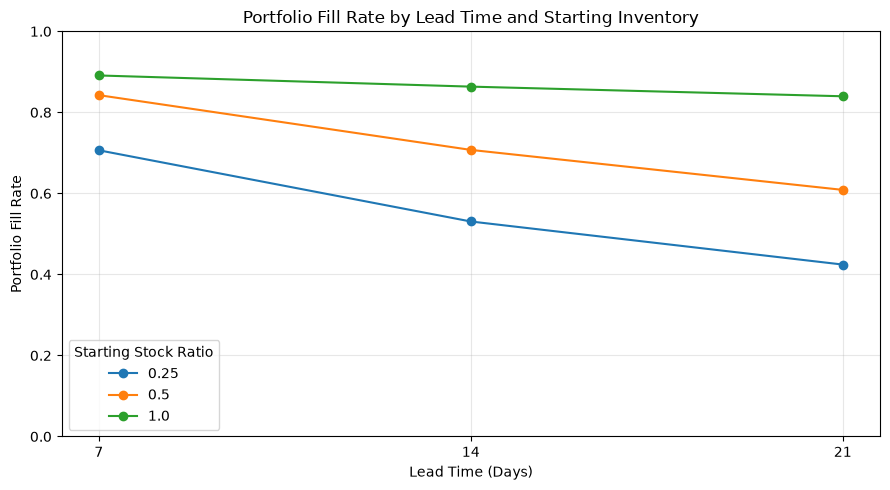

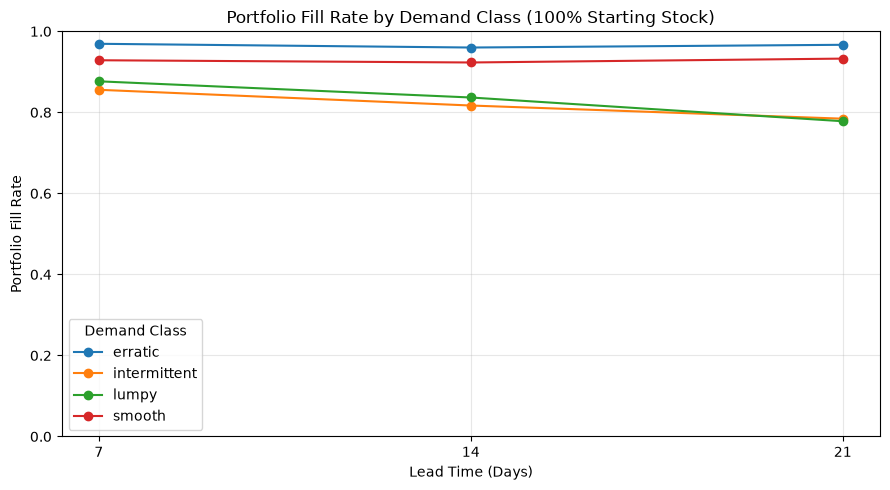

Inventory visualisations saved to: C:\Users\cjc72\Desktop\SalesForecasting\AI-Retail-Demand-Intelligence\graphs


In [56]:
import matplotlib.pyplot as plt
from pathlib import Path

RESULTS_DIR = Path(r'C:\Users\cjc72\Desktop\SalesForecasting\AI-Retail-Demand-Intelligence')

graphs_dir = RESULTS_DIR / "graphs"
graphs_dir.mkdir(parents=True, exist_ok=True)

# Portfolio fill rate across lead-time and starting-stock scenarios
fill_rate_pivot = corrected_inventory_summary.pivot(
    index="lead_time",
    columns="starting_stock_ratio",
    values="portfolio_fill_rate"
)

ax = fill_rate_pivot.plot(
    kind="line",
    marker="o",
    figsize=(9, 5)
)

ax.set_title("Portfolio Fill Rate by Lead Time and Starting Inventory")
ax.set_xlabel("Lead Time (Days)")
ax.set_ylabel("Portfolio Fill Rate")
ax.set_xticks([7, 14, 21])
ax.set_ylim(0, 1)
ax.legend(title="Starting Stock Ratio")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    graphs_dir / "inventory_fill_rate_by_scenario.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


# Demand-class comparison at 100% starting stock
class_plot_data = inventory_class_summary[
    (inventory_class_summary["starting_stock_ratio"] == 1.0)
    & (inventory_class_summary["demand_class"] != "no_demand")
]

class_pivot = class_plot_data.pivot(
    index="lead_time",
    columns="demand_class",
    values="portfolio_fill_rate"
)

ax = class_pivot.plot(
    kind="line",
    marker="o",
    figsize=(9, 5)
)

ax.set_title("Portfolio Fill Rate by Demand Class (100% Starting Stock)")
ax.set_xlabel("Lead Time (Days)")
ax.set_ylabel("Portfolio Fill Rate")
ax.set_xticks([7, 14, 21])
ax.set_ylim(0, 1)
ax.legend(title="Demand Class")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    graphs_dir / "inventory_fill_rate_by_demand_class.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Inventory visualisations saved to:", graphs_dir)

## Inventory Optimization Findings

A **Periodic Review, Order-Up-To (R, S)** policy was implemented using TFT P50 forecasts and empirically estimated safety stock.

### Key Findings
- Higher starting inventory consistently improved portfolio fill rate.
- Longer lead times increased lost sales and reduced demand fulfilment.
- At a 7-day lead time, portfolio fill rate improved from 70.64% to 89.11% as starting inventory increased from 25% to 100%.
- Intermittent and lumpy demand presented greater fulfilment challenges in several scenarios.
- The results demonstrate the trade-off between inventory availability and inventory held.

### Limitations
- **Initial inventory and supplier lead times are simulation assumptions.**
- Safety stock is based on limited historical forecast errors, not a guaranteed service level.
- The simulation covers a single replenishment cycle, not continuous replenishment.
- Actual inventory costs and realised savings cannot be established because the dataset lacks operational cost and inventory records.

### Conclusion
The simulation demonstrates how probabilistic forecasts and safety stock can support replenishment planning. The results are exploratory and should not be interpreted as proven operational improvements or cost savings.